# Customer Churn Classification with KNN
This comprehensive guide processes the Telco Customer Churn dataset, optimizes a Scikit-Learn pipeline, evaluates the model, saves/reloads it, and offers an interactive prediction program.

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from google.colab import files

# 1. Load data
df = pd.read_csv('/content/customer_churn.csv')
print(f"Initial Shape: {df.shape}")

# 2. Data Cleaning
# Strip whitespaces and force numerical conversion of TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

# Fill empty TotalCharges (typically new customers with tenure=0) with 0.0
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)

# Drop customerID if exists
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# Check duplicates
duplicates = df.duplicated().sum()
print(f"Duplicates found & removed: {duplicates}")
df = df.drop_duplicates()

print(f"Cleaned Shape: {df.shape}")
display(df.head())


Initial Shape: (7043, 21)
Duplicates found & removed: 22
Cleaned Shape: (7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Exploratory Data Analysis (EDA)
We will visualize the churn rate, inspect distributions, check for outliers, and display correlations.

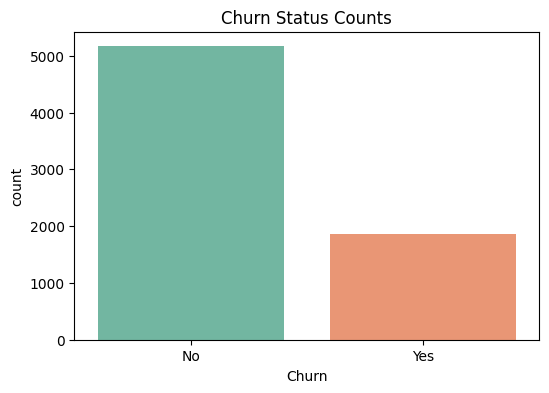

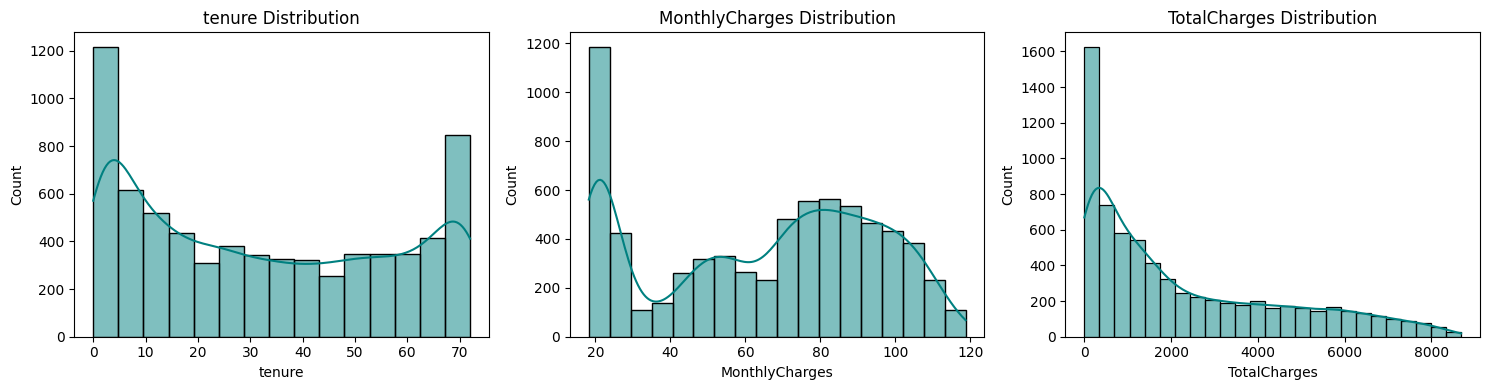

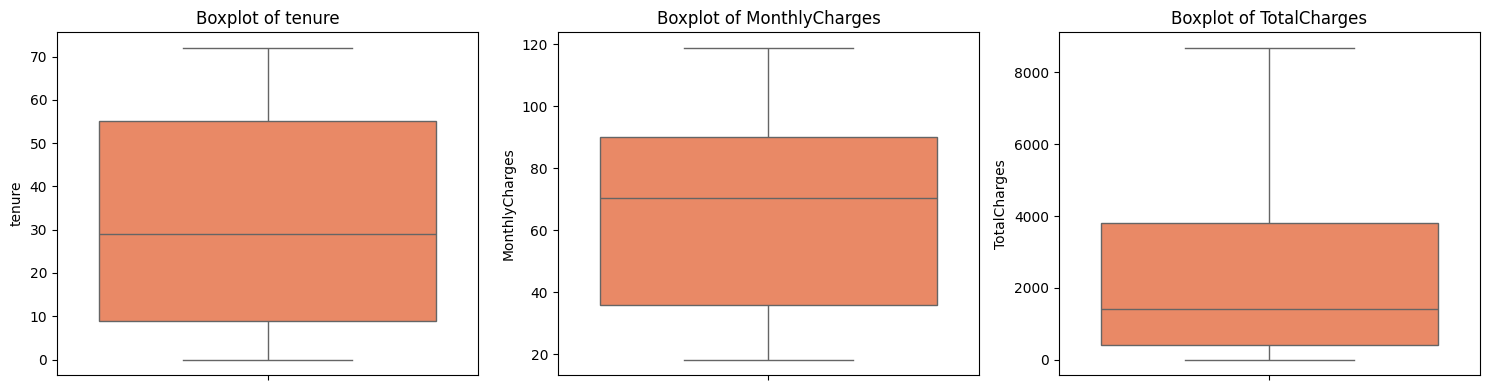

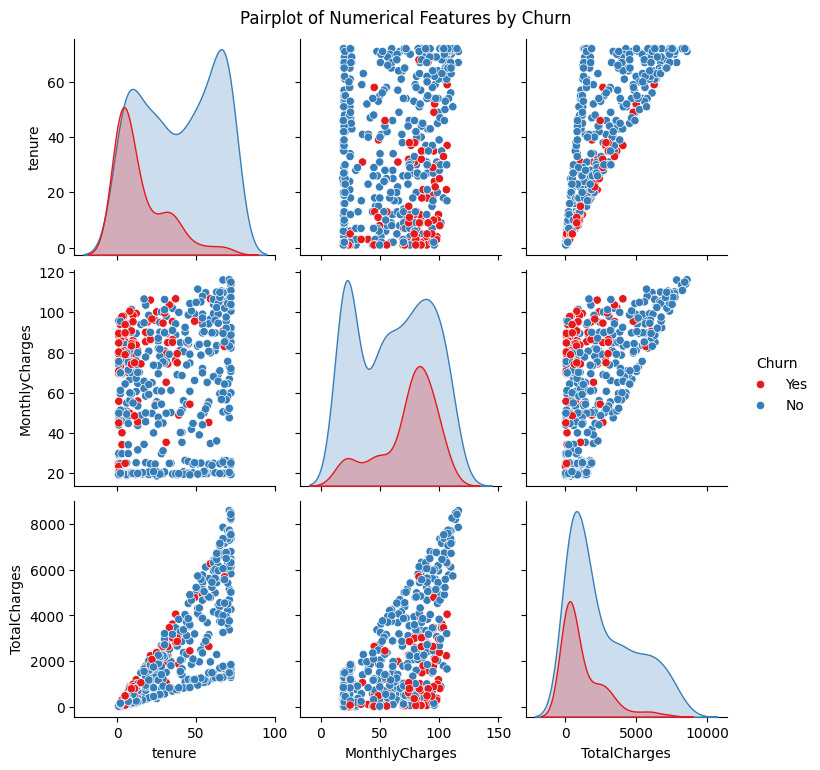

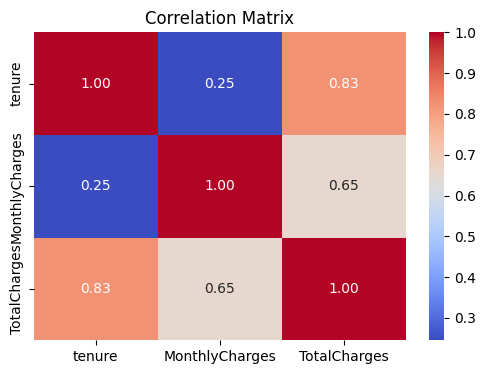

In [ ]:
# Churn distribution count plot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)
plt.title('Churn Status Counts')
plt.show()

# Histograms of numerical columns
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'{col} Distribution')
plt.tight_layout()
plt.show()

# Boxplots for Outlier Detection
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='coral')
    axes[i].set_title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

# Pairplot on sample
sample_df = df.sample(n=min(500, len(df)), random_state=42)
sns.pairplot(sample_df[num_cols + ['Churn']], hue='Churn', palette='Set1')
plt.suptitle('Pairplot of Numerical Features by Churn', y=1.02)
plt.show()

# Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()


### Graph Explanations:
1. **Churn Status Counts**: Shows our target variable is imbalanced (more 'No' than 'Yes').
2. **Histograms**: `tenure` has peaks at the start and end of lifetimes. `MonthlyCharges` is highly populated around low charges (~20) and mid-high range. `TotalCharges` is highly skewed to the right.
3. **Boxplots**: Demonstrates that there are no major outliers in these numerical ranges.
4. **Pairplot**: Highlights how tenure and charges overlap with the target class.
5. **Correlation Matrix**: Strong positive correlation between `tenure` and `TotalCharges` as expected.

## Pipeline Construction and Model Training
We separate features from targets, encode the target label, configure transformers inside a robust Pipeline, tune `k` using cross-validation, and perform evaluation.

In [ ]:
# Convert Target Label to binary numerical values
y = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0).values
X = df.drop(columns=['Churn'])

# Identify numerical & categorical columns dynamically
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X.columns if col not in num_features]

# Build preprocessors
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # Protects against any leakage during validation
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])

# Create model training pipeline
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

# Train test split (80/20 with stratification and random state)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Use GridSearchCV to find the optimal 'n_neighbors' (K value)
param_grid = {'classifier__n_neighbors': [3, 5, 7, 9, 11, 15]}
grid_search = GridSearchCV(full_pipeline, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(f"Best K Selected: {grid_search.best_params_['classifier__n_neighbors']}")

# Predict and evaluate
y_pred = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Best K Selected: 15

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1033
           1       0.61      0.52      0.56       372

    accuracy                           0.78      1405
   macro avg       0.72      0.70      0.71      1405
weighted avg       0.77      0.78      0.78      1405

Confusion Matrix:
[[908 125]
 [179 193]]


## Export the Model Pipeline and Simulate Reloading
We will save the pipeline object containing all prep strategies to `customer_churn_model.pkl` and programmatically trigger a file download.

In [ ]:
# Save the pipeline to file
with open('customer_churn_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)
print("Model successfully serialized to 'customer_churn_model.pkl'")

# Trigger automatic download in Google Colab
try:
    files.download('customer_churn_model.pkl')
    print("File download initiated.")
except Exception as e:
    print(f"Auto-download failed (normal if browser limits it): {e}")


Model successfully serialized to 'customer_churn_model.pkl'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File download initiated.


## Simulation of Future Reload & Interactive Inference
This section demonstrates how to reload the binary object and interactively test with user inputs.

In [ ]:
# Load the model as if in a new environment
with open('customer_churn_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)
print("Model reloaded successfully.")

def get_user_prediction():
    print("\nEnter customer information for prediction:")
    gender = input("Gender (Male/Female): ")
    senior = int(input("Senior Citizen (0/1): "))
    partner = input("Partner (Yes/No): ")
    dependents = input("Dependents (Yes/No): ")
    tenure = float(input("Tenure (months): "))
    phone = input("Phone Service (Yes/No): ")
    multiple = input("Multiple Lines (Yes/No/No phone service): ")
    internet = input("Internet Service (DSL/Fiber optic/No): ")
    security = input("Online Security (Yes/No/No internet service): ")
    backup = input("Online Backup (Yes/No/No internet service): ")
    protection = input("Device Protection (Yes/No/No internet service): ")
    support = input("Tech Support (Yes/No/No internet service): ")
    tv = input("Streaming TV (Yes/No/No internet service): ")
    movies = input("Streaming Movies (Yes/No/No internet service): ")
    contract = input("Contract (Month-to-month/One year/Two year): ")
    billing = input("Paperless Billing (Yes/No): ")
    payment = input("Payment Method (Electronic check/Mailed check/Bank transfer (automatic)/Credit card (automatic)): ")
    monthly = float(input("Monthly Charges ($): "))
    total = float(input("Total Charges ($): "))

    # Shape matching identical features
    input_data = pd.DataFrame([{
        'gender': gender, 'SeniorCitizen': senior, 'Partner': partner, 'Dependents': dependents,
        'tenure': tenure, 'PhoneService': phone, 'MultipleLines': multiple, 'InternetService': internet,
        'OnlineSecurity': security, 'OnlineBackup': backup, 'DeviceProtection': protection,
        'TechSupport': support, 'StreamingTV': tv, 'StreamingMovies': movies, 'Contract': contract,
        'PaperlessBilling': billing, 'PaymentMethod': payment, 'MonthlyCharges': monthly,
        'TotalCharges': total
    }])

    prediction = loaded_model.predict(input_data)[0]
    proba = loaded_model.predict_proba(input_data)[0]

    status = 'Likely to Churn' if prediction == 1 else 'Likely to Stay'
    print(f"\nPrediction Result: {status}")
    print(f"Confidence: Churn={proba[1]:.2%}, Stay={proba[0]:.2%}")
    print("Disclaimer: This prediction is a machine learning estimate, not a guarantee.")

# Run the function interactively
get_user_prediction()

Model reloaded successfully.

Enter customer information for prediction:
Gender (Male/Female): Female
Senior Citizen (0/1): 0
Partner (Yes/No): Yes
Dependents (Yes/No): Yes
Tenure (months): 5
Phone Service (Yes/No): Yes
Multiple Lines (Yes/No/No phone service): No
Internet Service (DSL/Fiber optic/No): No
Online Security (Yes/No/No internet service): Yes
Online Backup (Yes/No/No internet service): Yes
Device Protection (Yes/No/No internet service): Yes
Tech Support (Yes/No/No internet service): Yes
Streaming TV (Yes/No/No internet service): Yes
Streaming Movies (Yes/No/No internet service): Yes
Contract (Month-to-month/One year/Two year): One year
Paperless Billing (Yes/No): Yes
Payment Method (Electronic check/Mailed check/Bank transfer (automatic)/Credit card (automatic)): Credit card
Monthly Charges ($): 5000
Total Charges ($): 40000

Prediction Result: Likely to Stay
Confidence: Churn=13.33%, Stay=86.67%
Disclaimer: This prediction is a machine learning estimate, not a guarantee.
